# Case Study 22 — Significant but Irrelevant; Non-Significant but Promising

**Statistical vs practical significance · p-values, effect sizes and confidence intervals · break-even effects ·
equivalence and "worth-it" tests · how p-values depend on sample size · power and minimum detectable effects ·
"absence of evidence is not evidence of absence" · Bayesian probability of a worthwhile effect · value of
information · Type S and Type M errors · how to report an inconclusive result**

| | |
|---|---|
| **Domain** | Product and pricing experiments |
| **Stakeholders** | Head of Digital Product, Head of Cards, Finance business partner |
| **Difficulty** | Intermediate |
| **Importance** | 🔴 MUST GO THROUGH |
| **Builds on** | Cases 03, 04 (A/B tests, power), Case 19 (winner's curse) |
| **Data** | (A) A/B test of a checkout redesign, ~3 million visitors; (B) fee-waiver pilot, 1,200 customers |

> **This dataset is synthetic** and was generated to reproduce a realistic business scenario. It is not actual
> customer data. See `src/generate_data.py` (the file documents how the random stream was chosen; the choice never
> looks at p-values). A teaching-only answer key lists the true lifts and is opened only in Section 13.

**What you will learn**

1. A **tiny p-value** can go with an effect too small to matter, and a **large p-value** can go with an effect that
   would be very valuable. Significance answers "is it real?", not "does it matter?".
2. How to define **practical significance** up front, as a **break-even effect** from costs and benefits.
3. How to read a **confidence interval against a decision threshold**, which is more informative than a p-value.
4. How to treat an **inconclusive** result honestly, and how to decide whether more data is worth buying.

## Section 1 — Business context

Two experiment readouts arrive in the same week. The analyst's one-line summaries are:

> **A. Checkout redesign** (low-margin prepaid-recharge product): *"Conversion up from 5.00% to 5.10%. p = 0.0001.
> Highly significant. Recommend launch."* The redesign costs **₹60 lakh** to build and **₹12 lakh a year** to run, and
> each extra conversion earns about **₹40**.
>
> **B. Fee-waiver offer** (premium credit card): *"Conversion 9.0% in control vs 11.0% with the offer. p = 0.25. Not
> significant. Recommend dropping it."* The waiver costs about **₹120 per customer offered**, and each extra
> conversion is worth about **₹9,000** in margin.

The Head of Digital Product asks: *"Is it right to launch A and drop B? The p-values say so."*

## Section 2 — Business questions

1. Does the redesign (A) really increase conversion? By how much?
2. Is that increase **worth** the cost of building it?
3. Does the fee waiver (B) work? What can we say from a non-significant result?
4. Should we drop B, launch it, or collect more data? How much more?
5. How should both results be reported?

## Section 3 — Statistical translation

| # | Business question | Statistical question | Method |
|---|---|---|---|
| 1 | Is A real? How big? | Difference in conversion rates with a CI | Two-proportion z-test, CI, relative lift |
| 2 | Is it worth it? | Is the lift above the **break-even** lift? | Break-even from costs and margin; CI vs threshold; one-sided test |
| 3 | Does B work? | What effects are **compatible** with the data? | CI, power curve, equivalence test |
| 4 | Decide for B | Probability that the lift exceeds break-even; value of more data | Bayesian posterior, expected value, value of information |
| 5 | Reporting | How wrong can "significant" or "not significant" be? | Type S / Type M errors, decision matrix |

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "00_shared_resources").is_dir())
sys.path.insert(0, str(ROOT / "00_shared_resources"))
from utils import case_paths, save_table, fmt_p, rng_for_case
from statistical_tests import cohens_h
from plotting import set_style, save_fig, add_note, COLORS, CATEGORICAL, PRIMARY, HIGHLIGHT, INK, INK_MUTED

CASE_DIR = ROOT / "case_studies" / "22_statistical_vs_practical_significance"
PATHS = case_paths(CASE_DIR)
set_style()
pd.set_option("display.float_format", lambda v: f"{v:,.5f}")
rng = rng_for_case(2222)
pctfmt = plt.FuncFormatter(lambda v, _: f"{v:.1%}")
LAKH = 1e5

# Business assumptions (inputs from Finance, not estimated from the data)
A_BUILD, A_RUN, A_YEARS, A_MARGIN = 60 * LAKH, 12 * LAKH, 3, 40            # redesign: one-off build, yearly run cost, horizon, margin per extra conversion (₹)
B_COST, B_MARGIN, B_ELIGIBLE = 120, 9_000, 200_000                          # fee waiver: cost per customer offered, margin per extra conversion, eligible customers per year

def two_prop(x1, n1, x0, n0):
    p1, p0 = x1 / n1, x0 / n0
    pbar = (x1 + x0) / (n1 + n0)
    z = (p1 - p0) / np.sqrt(pbar * (1 - pbar) * (1 / n1 + 1 / n0))
    se = np.sqrt(p1 * (1 - p1) / n1 + p0 * (1 - p0) / n0)
    return {"p1": p1, "p0": p0, "diff": p1 - p0, "se": se, "z": z, "p": 2 * stats.norm.sf(abs(z)),
            "ci": (p1 - p0 - 1.96 * se, p1 - p0 + 1.96 * se)}

## Section 4 — Load the data

In [2]:
A = pd.read_csv(PATHS["data"] / "experiment_a_checkout.csv", parse_dates=["date"])
B = pd.read_csv(PATHS["data"] / "experiment_b_fee_waiver.csv")
print(f"A: {len(A)} rows ({A['date'].nunique()} days × 2 arms), {A['visitors'].sum():,} visitors;  B: {len(B):,} customers;  missing: {A.isna().sum().sum()} / {B.isna().sum().sum()}")
display(A.head(4)); display(B.head(4))
ga = A.groupby("arm")[["visitors", "conversions"]].sum()
gb = B.groupby("arm")["converted"].agg(["sum", "size"])
print(ga.assign(rate=ga["conversions"] / ga["visitors"]))
print(gb.assign(rate=gb["sum"] / gb["size"]))

A: 56 rows (28 days × 2 arms), 3,005,666 visitors;  B: 1,200 customers;  missing: 0 / 0


,date,arm,visitors,conversions
0,2026-01-05,control,47770,2483
1,2026-01-06,control,54048,2654
2,2026-01-07,control,53594,2703
3,2026-01-08,control,56634,2801


,customer_id,arm,converted
0,FW2210000,control,1
1,FW2210001,control,0
2,FW2210002,offer,0
3,FW2210003,offer,0


          visitors  conversions    rate
arm                                    
control    1505338        75545 0.05018
redesign   1500328        76769 0.05117
         sum  size    rate
arm                       
control   54   600 0.09000
offer     66   600 0.11000


## Section 5 — Experiment A: a large test

In [3]:
ra = two_prop(ga.loc["redesign", "conversions"], ga.loc["redesign", "visitors"], ga.loc["control", "conversions"], ga.loc["control", "visitors"])
srm = stats.chisquare(ga["visitors"].to_numpy())
h_a = cohens_h(ra["p1"], ra["p0"])
res_a = pd.DataFrame({"estimate": [ra["p0"], ra["p1"], 100 * ra["diff"], 100 * ra["diff"] / (100 * ra["p0"]), h_a, ra["z"], ra["p"]],
                      "ci_low": [np.nan, np.nan, 100 * ra["ci"][0], 100 * ra["ci"][0] / (100 * ra["p0"]), np.nan, np.nan, np.nan],
                      "ci_high": [np.nan, np.nan, 100 * ra["ci"][1], 100 * ra["ci"][1] / (100 * ra["p0"]), np.nan, np.nan, np.nan]},
                     index=["conversion, control", "conversion, redesign", "absolute lift (percentage points)", "relative lift (share of control rate)", "Cohen's h", "z", "p-value"])
save_table(res_a, "experiment_a_results", PATHS["tables"])
display(res_a)
print(f"Sample-ratio check (visitors split 50:50?): χ² = {srm.statistic:.2f}, p = {srm.pvalue:.3f}")

,estimate,ci_low,ci_high
"conversion, control",0.05018,NaN,NaN
"conversion, redesign",0.05117,NaN,NaN
absolute lift (percentage points),0.09834,0.04875,0.14793
relative lift (share of control rate),0.01960,0.00971,0.02948
Cohen's h,0.00448,NaN,NaN
z,3.88655,NaN,NaN
p-value,0.00010,NaN,NaN


Sample-ratio check (visitors split 50:50?): χ² = 8.35, p = 0.004


,lift (pp),ci_low,ci_high,p
week,,,,
1,0.19094,0.09166,0.29022,0.00016
2,0.09682,-0.00196,0.19560,0.05471
3,0.02400,-0.07525,0.12326,0.63549
4,0.08151,-0.01792,0.18094,0.10812


First day on which the cumulative p-value is < 0.05 AND stays below for the rest of the test: 4


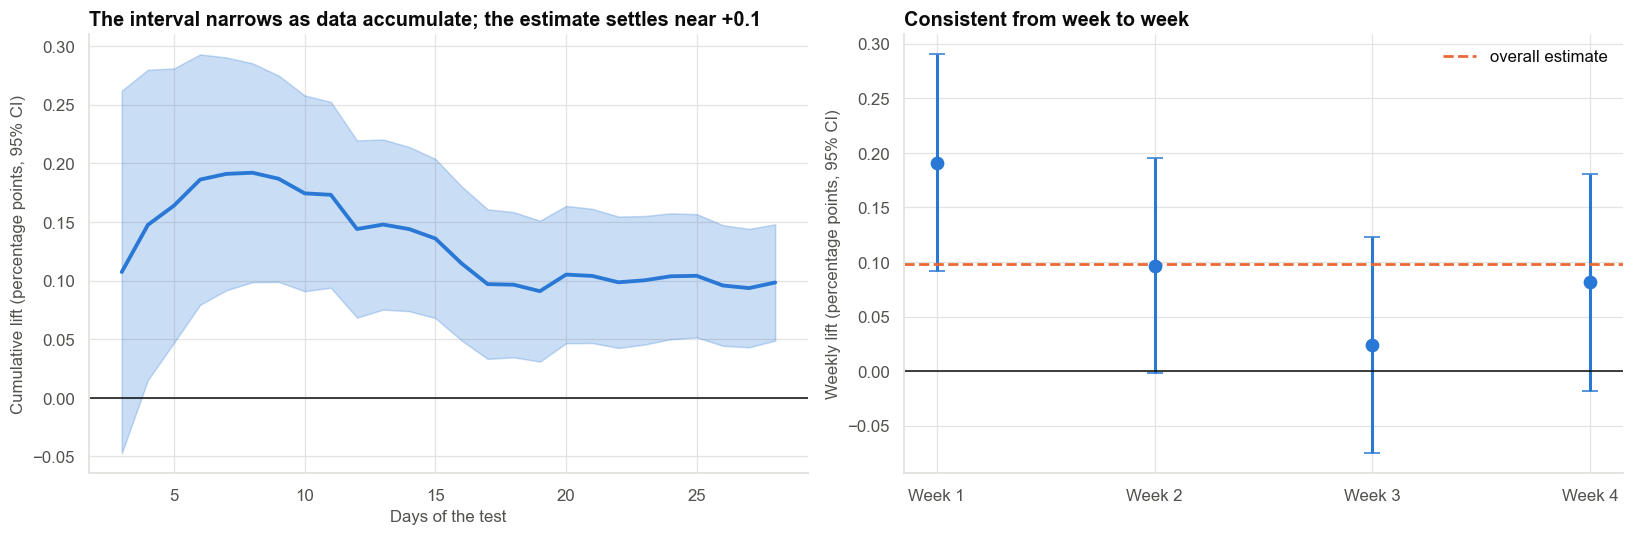

In [4]:
# How the evidence accumulates, week by week and day by day.
d = A.pivot_table(index="date", columns="arm", values=["visitors", "conversions"], aggfunc="sum")
cum = d.cumsum()
rows = []
for day in range(3, len(cum) + 1):
    c = cum.iloc[day - 1]
    r_ = two_prop(c[("conversions", "redesign")], c[("visitors", "redesign")], c[("conversions", "control")], c[("visitors", "control")])
    rows.append({"day": day, "lift (pp)": 100 * r_["diff"], "ci_low": 100 * r_["ci"][0], "ci_high": 100 * r_["ci"][1], "p": r_["p"]})
path_a = pd.DataFrame(rows).set_index("day")
weekly = []
for w in range(4):
    sub = A[(A["date"] >= A["date"].min() + pd.Timedelta(days=7 * w)) & (A["date"] < A["date"].min() + pd.Timedelta(days=7 * (w + 1)))].groupby("arm")[["visitors", "conversions"]].sum()
    r_ = two_prop(sub.loc["redesign", "conversions"], sub.loc["redesign", "visitors"], sub.loc["control", "conversions"], sub.loc["control", "visitors"])
    weekly.append({"week": w + 1, "lift (pp)": 100 * r_["diff"], "ci_low": 100 * r_["ci"][0], "ci_high": 100 * r_["ci"][1], "p": r_["p"]})
weekly = pd.DataFrame(weekly).set_index("week")
save_table(weekly, "experiment_a_weekly", PATHS["tables"])
display(weekly)
print(f"First day on which the cumulative p-value is < 0.05 AND stays below for the rest of the test: "
      f"{next((int(i) for i in path_a.index if (path_a.loc[i:, 'p'] < 0.05).all()), None)}")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
ax = axes[0]
ax.fill_between(path_a.index, path_a["ci_low"], path_a["ci_high"], color=PRIMARY, alpha=0.25)
ax.plot(path_a.index, path_a["lift (pp)"], color=PRIMARY, lw=2.5)
ax.axhline(0, color=INK, lw=1)
ax.set(xlabel="Days of the test", ylabel="Cumulative lift (percentage points, 95% CI)", title="The interval narrows as data accumulate; the estimate settles near +0.1")
ax = axes[1]
ax.errorbar(weekly.index, weekly["lift (pp)"], yerr=[weekly["lift (pp)"] - weekly["ci_low"], weekly["ci_high"] - weekly["lift (pp)"]], fmt="o", color=PRIMARY, capsize=5, ms=8, lw=2)
ax.axhline(0, color=INK, lw=1); ax.axhline(100 * ra["diff"], color=HIGHLIGHT, ls="--", lw=1.8, label="overall estimate")
ax.set_xticks(weekly.index, [f"Week {w}" for w in weekly.index])
ax.set(ylabel="Weekly lift (percentage points, 95% CI)", title="Consistent from week to week"); ax.legend(frameon=False)
fig.tight_layout()
save_fig(fig, "fig01_experiment_a", PATHS["figures"])
plt.show()

**Observation.** Conversion rose from 5.02% to 5.12%: an absolute lift of about **0.10 percentage points** (95% CI
0.05 to 0.15), a **relative** lift of about **2%**. The z-statistic is about 3.9 and **p ≈ 0.0001**: this is a
statistically significant result. The lift is positive in all four weeks, but largest in week 1 (0.19 points) and
weaker afterwards, so a novelty effect is possible. One data-quality flag: the visitor split is not exactly 50:50
(χ² = 8.35, p = 0.004; control has 0.3% more visitors). The imbalance is tiny, but a real team would find its cause
before trusting the result (in this synthetic data, daily traffic per arm was generated with independent noise).

**But note the size.** The CI says the true lift is between about **0.05 and 0.15 percentage points**: out of 1,000
visitors, between 0.5 and 1.5 additional conversions. Cohen's h is about 0.004, a tiny effect by any convention.
Statistical significance here is a product of **sample size**: with 1.5 million visitors in each arm, even a very
small lift becomes detectable.

## Section 6 — Is it worth it? The break-even lift

**Statistical significance asks whether an effect is non-zero. A business decision asks whether it is bigger than its
cost.** We define the practically relevant threshold *before* looking at the p-value, from the economics:

In [5]:
visits_year = ga["visitors"].sum() / A["date"].nunique() * 365
cost_year = A_BUILD / A_YEARS + A_RUN
be_a = cost_year / (visits_year * A_MARGIN)                               # break-even absolute lift (proportion)
benefit = lambda lift: lift * visits_year * A_MARGIN
net = lambda lift: benefit(lift) - cost_year
econ_a = pd.DataFrame({"lift (pp)": [100 * ra["ci"][0], 100 * ra["diff"], 100 * ra["ci"][1], 100 * be_a],
                       "extra conversions per year": [ra["ci"][0] * visits_year, ra["diff"] * visits_year, ra["ci"][1] * visits_year, be_a * visits_year],
                       "benefit per year (₹ lakh)": [benefit(ra["ci"][0]) / LAKH, benefit(ra["diff"]) / LAKH, benefit(ra["ci"][1]) / LAKH, benefit(be_a) / LAKH],
                       "net of cost, per year (₹ lakh)": [net(ra["ci"][0]) / LAKH, net(ra["diff"]) / LAKH, net(ra["ci"][1]) / LAKH, 0.0]},
                      index=["CI lower limit", "estimate", "CI upper limit", "BREAK-EVEN"])
save_table(econ_a, "experiment_a_economics", PATHS["tables"])
print(f"Annual visitors {visits_year / 1e6:.1f} million; annual cost = ₹{A_BUILD / LAKH:.0f} lakh ÷ {A_YEARS} years + ₹{A_RUN / LAKH:.0f} lakh = ₹{cost_year / LAKH:.0f} lakh; "
      f"margin ₹{A_MARGIN} per extra conversion → break-even lift {100 * be_a:.2f} percentage points")
display(econ_a)
# One-sided test: H0 'lift ≥ break-even' against H1 'lift < break-even'.
z_be = (ra["diff"] - be_a) / ra["se"]
p_below = stats.norm.cdf(z_be)
print(f"One-sided test that the lift is BELOW break-even: z = {z_be:.1f}, p = {fmt_p(p_below)}")

Annual visitors 39.2 million; annual cost = ₹60 lakh ÷ 3 years + ₹12 lakh = ₹32 lakh; margin ₹40 per extra conversion → break-even lift 0.20 percentage points


,lift (pp),extra conversions per year,benefit per year (₹ lakh),"net of cost, per year (₹ lakh)"
CI lower limit,0.04875,"19,099.26821",7.63971,-24.36029
estimate,0.09834,"38,530.67704",15.41227,-16.58773
CI upper limit,0.14793,"57,962.08586",23.18483,-8.81517
BREAK-EVEN,0.20418,"80,000.00000",32.00000,0.00000


One-sided test that the lift is BELOW break-even: z = -4.2, p = < 0.001


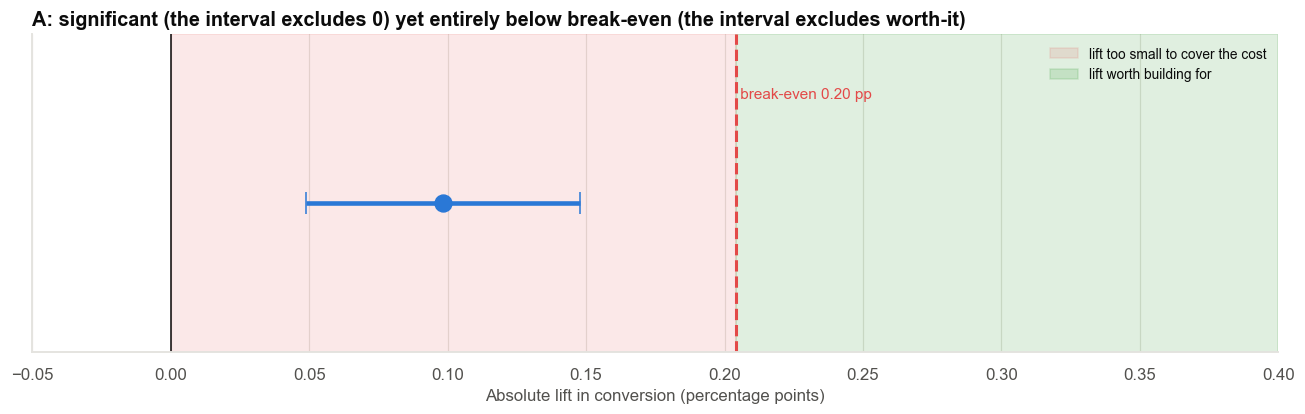

In [6]:
fig, ax = plt.subplots(figsize=(12, 3.9))
ax.axvspan(0, 100 * be_a, color=COLORS["red"], alpha=0.12, label="lift too small to cover the cost")
ax.axvspan(100 * be_a, 0.4, color=COLORS["green"], alpha=0.12, label="lift worth building for")
ax.errorbar(100 * ra["diff"], 0, xerr=[[100 * (ra["diff"] - ra["ci"][0])], [100 * (ra["ci"][1] - ra["diff"])]], fmt="o", color=PRIMARY, ms=11, capsize=7, lw=3)
ax.axvline(0, color=INK, lw=1); ax.axvline(100 * be_a, color=COLORS["red"], ls="--", lw=2)
ax.text(100 * be_a, 0.28, f" break-even {100 * be_a:.2f} pp", color=COLORS["red"], fontsize=10)
ax.set_xlim(-0.05, 0.4); ax.set_ylim(-0.4, 0.45); ax.set_yticks([])
ax.set(xlabel="Absolute lift in conversion (percentage points)", title="A: significant (the interval excludes 0) yet entirely below break-even (the interval excludes worth-it)")
ax.legend(frameon=False, loc="upper right", fontsize=9)
fig.tight_layout()
save_fig(fig, "fig02_a_vs_breakeven", PATHS["figures"])
plt.show()

**Observation.** At 39 million visitors a year and ₹40 per extra conversion, the redesign needs a lift of about
**0.20 percentage points** just to cover its annual cost (₹32 lakh = ₹60 lakh ÷ 3 years + ₹12 lakh running cost). The
measured lift is about **0.10 points**, and the **entire confidence interval (0.05 to 0.15) lies below break-even**. At
the estimated lift the redesign **loses about ₹17 lakh a year**; even at the upper limit it loses about ₹9 lakh. A
one-sided test that the true lift is *below* break-even gives p < 0.001.

**Interpretation.** Result A is **statistically significant and practically irrelevant**. The analyst's "p = 0.0001,
launch" confuses the question "is there an effect?" with "is the effect worth having?". The confidence interval,
compared with the break-even threshold, answers the business question directly, and the answer is **do not build it**
(at these economics).

**Caveats.** The margin per conversion and the horizon are assumptions from Finance. If the redesign also reduced
support costs or lifted a more valuable product, the break-even would move. The point is to **state the threshold
first**, then ask whether the interval is above it.

### 6.1 How a p-value depends on the sample size

,standard error (pp),expected z,typical p-value,chance of p < 0.05,95% CI half-width (pp)
visitors per arm,,,,,
10000,0.30822,0.32444,0.74560,0.06214,0.60411
30000,0.17795,0.56195,0.57415,0.08688,0.34878
100000,0.09747,1.02598,0.30490,0.17656,0.19104
300000,0.05627,1.77705,0.07556,0.42751,0.11030
1000000,0.03082,3.24443,0.00118,0.90050,0.06041
3000000,0.01780,5.61951,0.00000,0.99987,0.03488
10000000,0.00975,10.25978,0.00000,1.00000,0.01910


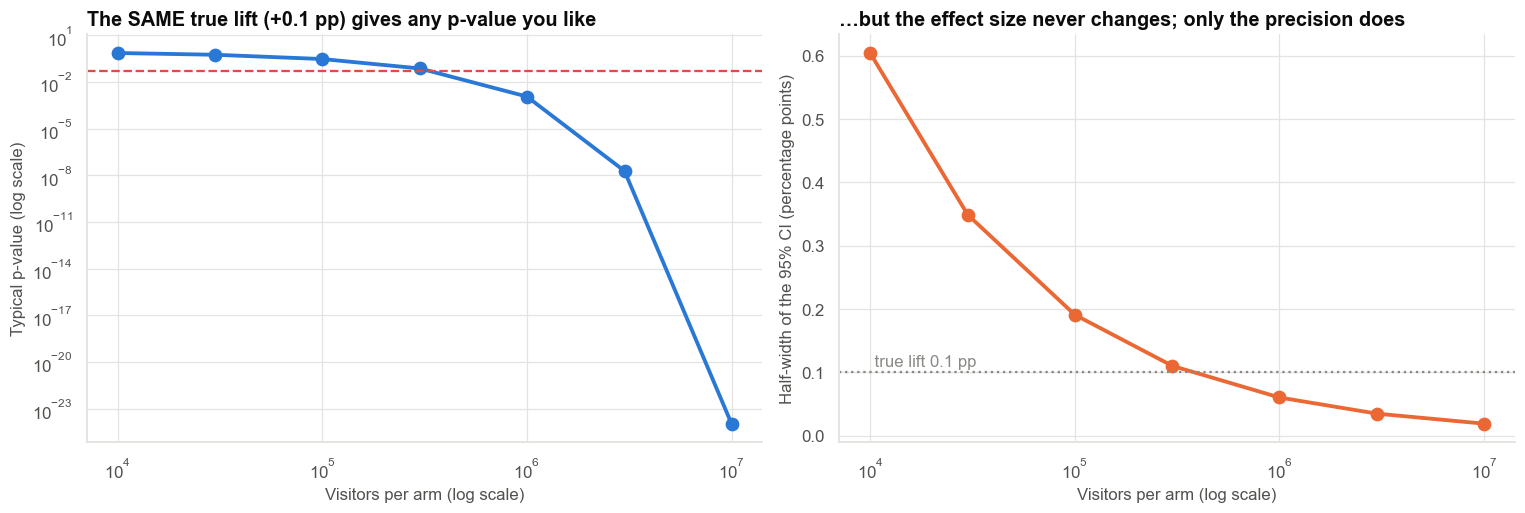

In [7]:
true_lift = 0.0010
base = 0.05
sizes = np.array([10_000, 30_000, 100_000, 300_000, 1_000_000, 3_000_000, 10_000_000])
se_n = np.sqrt(2 * base * (1 - base) / sizes)
z_expected = true_lift / se_n
power = stats.norm.sf(1.96 - z_expected) + stats.norm.cdf(-1.96 - z_expected)
size_tbl = pd.DataFrame({"visitors per arm": sizes, "standard error (pp)": 100 * se_n, "expected z": z_expected,
                         "typical p-value": 2 * stats.norm.sf(z_expected), "chance of p < 0.05": power,
                         "95% CI half-width (pp)": 196 * se_n}).set_index("visitors per arm")
save_table(size_tbl, "pvalue_vs_sample_size", PATHS["tables"])
display(size_tbl)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
ax = axes[0]
ax.semilogx(sizes, size_tbl["typical p-value"], "o-", color=PRIMARY, lw=2.5, ms=8)
ax.axhline(0.05, color=COLORS["red"], ls="--", lw=1.5); ax.set_yscale("log")
ax.set(xlabel="Visitors per arm (log scale)", ylabel="Typical p-value (log scale)", title="The SAME true lift (+0.1 pp) gives any p-value you like")
ax = axes[1]
ax.semilogx(sizes, size_tbl["95% CI half-width (pp)"], "o-", color=HIGHLIGHT, lw=2.5, ms=8)
ax.axhline(100 * true_lift, color=INK_MUTED, ls=":"); ax.text(sizes[0], 100 * true_lift + 0.01, " true lift 0.1 pp", color=INK_MUTED)
ax.set(xlabel="Visitors per arm (log scale)", ylabel="Half-width of the 95% CI (percentage points)", title="…but the effect size never changes; only the precision does")
fig.tight_layout()
save_fig(fig, "fig03_pvalue_vs_n", PATHS["figures"])
plt.show()

**Observation.** For the **same true lift** of 0.1 points, the typical p-value goes from about 0.75 with 10,000
visitors per arm to below 10⁻¹⁰ with 10 million. Chance of reaching p < 0.05 goes from about 6% to 100%. Meanwhile the effect never
changes: only the CI width does.

**Interpretation.** A p-value is a function of **effect size and sample size**. With enough data, any non-zero effect
becomes "significant". That is why **significance cannot be the criterion for "does it matter"**. The criterion is
the **effect size relative to a threshold set by the business**.

## Section 7 — Experiment B: a small pilot

In [8]:
rb = two_prop(gb.loc["offer", "sum"], gb.loc["offer", "size"], gb.loc["control", "sum"], gb.loc["control", "size"])
nB = int(gb.loc["offer", "size"])
res_b = pd.DataFrame({"estimate": [rb["p0"], rb["p1"], 100 * rb["diff"], 100 * rb["diff"] / (100 * rb["p0"]), cohens_h(rb["p1"], rb["p0"]), rb["z"], rb["p"]],
                      "ci_low": [np.nan, np.nan, 100 * rb["ci"][0], 100 * rb["ci"][0] / (100 * rb["p0"]), np.nan, np.nan, np.nan],
                      "ci_high": [np.nan, np.nan, 100 * rb["ci"][1], 100 * rb["ci"][1] / (100 * rb["p0"]), np.nan, np.nan, np.nan]},
                     index=["conversion, control", "conversion, offer", "absolute lift (percentage points)", "relative lift (share of control rate)", "Cohen's h", "z", "p-value"])
save_table(res_b, "experiment_b_results", PATHS["tables"])
display(res_b)
be_b = B_COST / B_MARGIN
print(f"Break-even lift for B: ₹{B_COST} cost ÷ ₹{B_MARGIN:,} margin per extra conversion = {100 * be_b:.2f} percentage points per customer offered")

,estimate,ci_low,ci_high
"conversion, control",0.09000,NaN,NaN
"conversion, offer",0.11000,NaN,NaN
absolute lift (percentage points),2.00000,-1.39293,5.39293
relative lift (share of control rate),0.22222,-0.15477,0.59921
Cohen's h,0.06675,NaN,NaN
z,1.15470,NaN,NaN
p-value,0.24821,NaN,NaN


Break-even lift for B: ₹120 cost ÷ ₹9,000 margin per extra conversion = 1.33 percentage points per customer offered


**Observation.** Conversion was **9.0%** in control and **11.0%** with the offer: an estimated lift of **+2.0
percentage points (+22% relative)**. The p-value is **0.25**, not significant, and the 95% CI is wide: about **−1.4 to
+5.4 percentage points**.

**What a non-significant result means:**
- It does **not** show that the effect is zero. The data are **compatible with** a harmful effect (−1.4), no effect, and
  a very valuable one (+5.4).
- It means the pilot is **too small to distinguish** a real lift from chance. With 600 customers per arm and 9–11%
  conversion, the standard error is 1.7 points.

**"Absence of evidence is not evidence of absence."** The analyst's "no effect, drop it" is a statement about what
the pilot **could not show**, not about what the offer does.

### 7.1 What could this pilot detect? Power and the minimum detectable effect

Minimum detectable effect at 80% power: 4.8 percentage points; break-even is 1.3; the pilot's estimate is 2.0


,power with 600 per arm
true lift (pp),
0.50000,0.05961
1.00000,0.08902
1.33333,0.12023
2.00000,0.21143
3.00000,0.41033
4.00000,0.63710


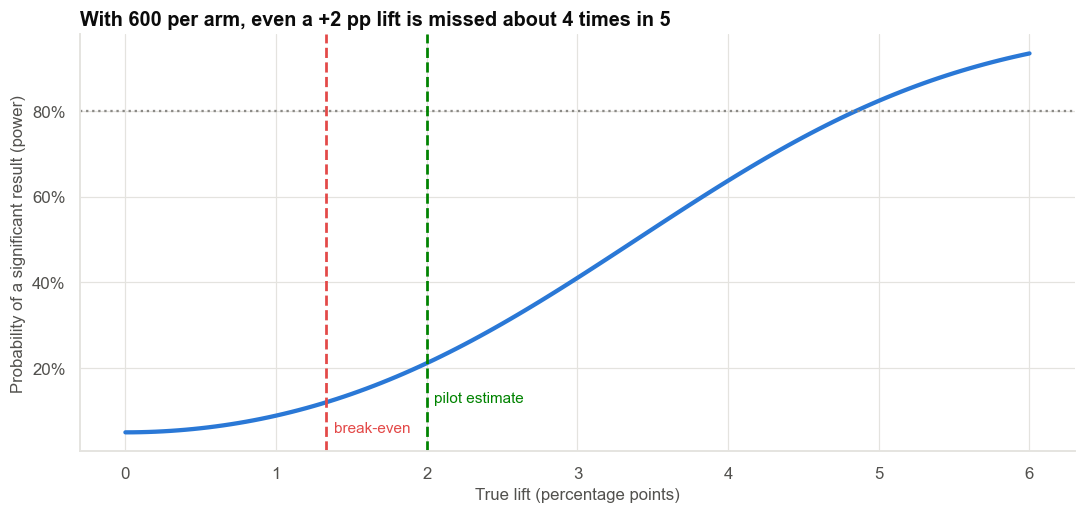

In [9]:
se_b = np.sqrt(rb["p0"] * (1 - rb["p0"]) / nB + rb["p1"] * (1 - rb["p1"]) / nB)
lifts = np.linspace(0, 0.06, 121)
pw = stats.norm.sf(1.96 - lifts / se_b) + stats.norm.cdf(-1.96 - lifts / se_b)
mde_b = (1.96 + 0.8416) * se_b
rows = [(lift_, stats.norm.sf(1.96 - lift_ / se_b) + stats.norm.cdf(-1.96 - lift_ / se_b)) for lift_ in [0.005, 0.01, be_b, 0.02, 0.03, 0.04]]
pw_tbl = pd.DataFrame(rows, columns=["true lift", "power with 600 per arm"]); pw_tbl["true lift (pp)"] = 100 * pw_tbl["true lift"]
pw_tbl = pw_tbl.set_index("true lift (pp)")[["power with 600 per arm"]]
save_table(pw_tbl, "experiment_b_power", PATHS["tables"])
print(f"Minimum detectable effect at 80% power: {100 * mde_b:.1f} percentage points; break-even is {100 * be_b:.1f}; the pilot's estimate is {100 * rb['diff']:.1f}")
display(pw_tbl)
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.plot(100 * lifts, pw, color=PRIMARY, lw=2.8)
ax.axhline(0.8, color=INK_MUTED, ls=":"); ax.axvline(100 * be_b, color=COLORS["red"], ls="--", lw=1.8); ax.axvline(100 * rb["diff"], color=COLORS["green"], ls="--", lw=1.8)
ax.text(100 * be_b + 0.05, 0.05, "break-even", color=COLORS["red"], fontsize=10); ax.text(100 * rb["diff"] + 0.05, 0.12, "pilot estimate", color=COLORS["green"], fontsize=10)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set(xlabel="True lift (percentage points)", ylabel="Probability of a significant result (power)", title="With 600 per arm, even a +2 pp lift is missed about 4 times in 5")
fig.tight_layout()
save_fig(fig, "fig04_b_power", PATHS["figures"])
plt.show()

**Observation.** With 600 customers per arm, this pilot has only about **21% power** to detect a true lift of 2
points, about 12% at the break-even lift of 1.3 points, and it would only have **80% power for lifts above about
4.8 points**. A non-significant result was the **likely** outcome even if the offer works as well as we hoped.

**Interpretation.** Reading a **non-significant** result requires knowing the **power**. A study with about 21% power fails to
find a real effect 3 times out of 4. (Do not compute "observed power" from the observed lift: it is a one-to-one
function of the p-value and adds nothing. Use the **CI** and **power at plausible effect sizes** instead.)

## Section 8 — Deciding under uncertainty for B

### 8.1 How likely is it that the offer is worth having?
We combine the pilot with a **weakly informative prior** that most fee-waiver offers have small effects (prior mean 0,
SD 3 percentage points), and ask for the probability that the true lift exceeds the break-even of 1.3 points.

In [10]:
prior_m, prior_sd = 0.0, 0.03
est, se = rb["diff"], se_b
def posterior(est, se, prior_m=prior_m, prior_sd=prior_sd):
    prec = 1 / se ** 2 + 1 / prior_sd ** 2
    m = (est / se ** 2 + prior_m / prior_sd ** 2) / prec
    return m, np.sqrt(1 / prec)
pm, ps = posterior(est, se)
rows = []
for name, (m_, s_) in {"flat prior (pilot only)": (est, se), "weak prior N(0, 3 pp)": (pm, ps)}.items():
    rows.append({"prior": name, "posterior mean lift (pp)": 100 * m_, "95% credible interval low (pp)": 100 * (m_ - 1.96 * s_), "95% credible interval high (pp)": 100 * (m_ + 1.96 * s_),
                 "P(lift > 0)": stats.norm.sf(0, m_, s_), "P(lift > break-even)": stats.norm.sf(be_b, m_, s_),
                 "expected net value per customer offered (₹)": m_ * B_MARGIN - B_COST,
                 "expected net value per year, 200,000 customers (₹ lakh)": (m_ * B_MARGIN - B_COST) * B_ELIGIBLE / LAKH})
post = pd.DataFrame(rows).set_index("prior")
save_table(post, "experiment_b_posterior", PATHS["tables"])
post

,posterior mean lift (pp),95% credible interval low (pp),95% credible interval high (pp),P(lift > 0),P(lift > break-even),expected net value per customer offered (₹),"expected net value per year, 200,000 customers (₹ lakh)"
prior,,,,,,,
flat prior (pilot only),2.00000,-1.39293,5.39293,0.87602,0.64992,60.00000,120.00000
"weak prior N(0, 3 pp)",1.50042,-1.43836,4.43919,0.84151,0.54436,15.03751,30.07502


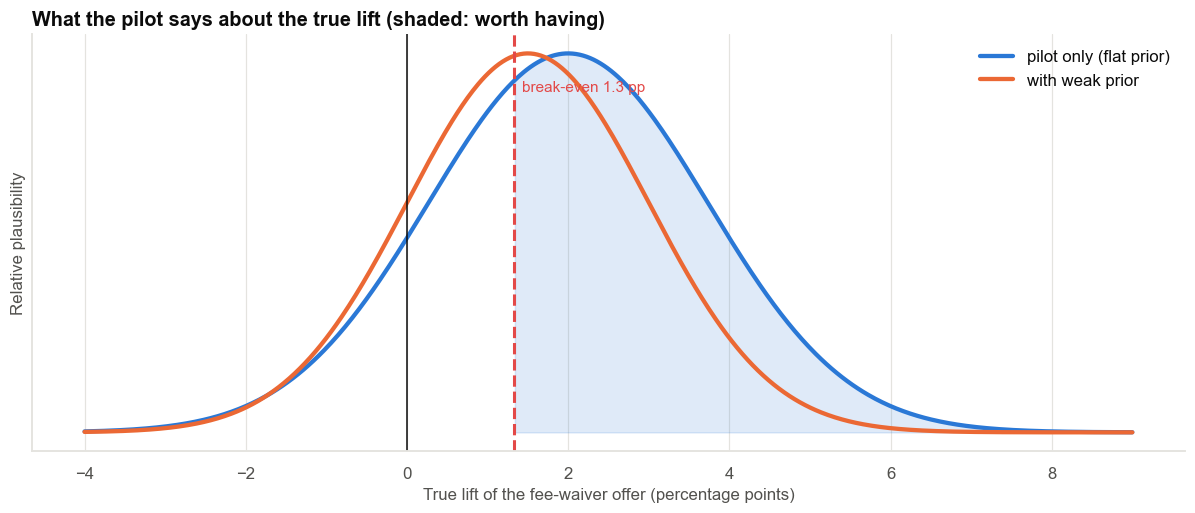

In [11]:
x = np.linspace(-0.04, 0.09, 600)
fig, ax = plt.subplots(figsize=(11, 4.8))
for (m_, s_), c, lab in [((est, se), COLORS["blue"], "pilot only (flat prior)"), ((pm, ps), COLORS["orange"], "with weak prior")]:
    y = stats.norm.pdf(x, m_, s_)
    ax.plot(100 * x, y / y.max(), color=c, lw=2.8, label=lab)
ax.axvline(0, color=INK, lw=1); ax.axvline(100 * be_b, color=COLORS["red"], ls="--", lw=2)
ax.fill_between(100 * x, 0, stats.norm.pdf(x, est, se) / stats.norm.pdf(est, est, se), where=x > be_b, color=COLORS["blue"], alpha=0.15)
ax.text(100 * be_b + 0.1, 0.9, f"break-even {100 * be_b:.1f} pp", color=COLORS["red"], fontsize=10)
ax.set_yticks([]); ax.set(xlabel="True lift of the fee-waiver offer (percentage points)", ylabel="Relative plausibility", title="What the pilot says about the true lift (shaded: worth having)")
ax.legend(frameon=False)
fig.tight_layout()
save_fig(fig, "fig05_b_posterior", PATHS["figures"])
plt.show()

**Observation.** From the pilot alone, the probability that the lift is **positive** is about **88%** and that it
exceeds the **break-even** is about **65%**; with the weak prior these are about 84% and 54%. The expected net value
of launching is **positive** (about ₹60 per customer offered with the flat prior; about ₹15 with the weak prior), but the
**interval is wide**: the downside is real.

**Interpretation.** This is a different framing from "p = 0.25: not significant". It says: *the offer is more
likely than not to be worth having, and we are far from certain*. A Bayesian posterior mixes the data with prior
assumptions, so the prior should be stated and varied (here, the answer is similar for both).

### 8.2 Is it worth collecting more data? A value-of-information calculation
We compare three strategies under the posterior (weak prior): **launch now**, **drop now**, or **run a bigger
follow-up test** (4,000 per arm, costing about ₹8 lakh in foregone margin and effort) and then launch only if the
updated expected net value is positive.

In [12]:
N_SIM = 200_000
FOLLOW_N, FOLLOW_COST = 4_000, 8 * LAKH
true_lift_draw = rng.normal(pm, ps, N_SIM)
se_f = np.sqrt(2 * 0.08 * 0.92 / FOLLOW_N)
est_f = rng.normal(true_lift_draw, se_f)
prec_new = 1 / ps ** 2 + 1 / se_f ** 2
pm_new = (pm / ps ** 2 + est_f / se_f ** 2) / prec_new
payoff = lambda lift: (lift * B_MARGIN - B_COST) * B_ELIGIBLE
launch_now = payoff(true_lift_draw).mean()
drop_now = 0.0
decide_launch = (pm_new * B_MARGIN - B_COST) > 0
test_then_decide = np.where(decide_launch, payoff(true_lift_draw), 0.0).mean() - FOLLOW_COST
perfect = np.maximum(payoff(true_lift_draw), 0).mean()
voi = pd.DataFrame({"expected value (₹ lakh per year)": [launch_now / LAKH, drop_now / LAKH, test_then_decide / LAKH, perfect / LAKH],
                    "comment": ["pay the fee waiver to everyone eligible", "walk away", f"follow-up test of {FOLLOW_N:,} per arm, then decide",
                                "an oracle who knew the true lift (upper bound)"]},
                   index=["launch now", "drop now (the analyst's advice)", "bigger test, then decide", "perfect information (EVPI)"])
save_table(voi, "value_of_information", PATHS["tables"])
print(f"Expected value of perfect information: ₹{(perfect - max(launch_now, 0)) / LAKH:.1f} lakh per year; follow-up test costs ₹{FOLLOW_COST / LAKH:.0f} lakh")
print(f"Probability the follow-up test would lead to 'launch': {decide_launch.mean():.0%}")
voi

Expected value of perfect information: ₹93.4 lakh per year; follow-up test costs ₹8 lakh
Probability the follow-up test would lead to 'launch': 55%


,expected value (₹ lakh per year),comment
launch now,29.72684,pay the fee waiver to everyone eligible
drop now (the analyst's advice),0.00000,walk away
"bigger test, then decide",107.32082,"follow-up test of 4,000 per arm, then decide"
perfect information (EVPI),123.12872,an oracle who knew the true lift (upper bound)


**Observation.** "Drop now" is worth zero by definition; "launch now" has a small positive expected value but a
substantial chance of losing money; **running a follow-up test before deciding has the highest expected value** (about ₹107 lakh a year after
paying for the test, against ₹30 lakh for launching now), capturing most (about 87%) of the ₹123 lakh an all-knowing oracle would add. The pilot's non-significance
did not make dropping the idea the best move.

**Interpretation.** When an effect is **plausibly valuable**, the cost of resolving the uncertainty is small compared
with the stakes, and the answer can change the decision, **more data is worth buying**. When (as in A) the whole interval
is below break-even, more data cannot change the decision, and **stopping is right**.

## Section 9 — Significant results in small studies can mislead too: Type S and Type M errors

If we only act on significant results from underpowered studies, the **significant** estimates are **exaggerated** (Type
M, magnitude) and sometimes have the **wrong sign** (Type S). Simulate many pilots like B, with a true lift of
+2.0 points:

,value
power: share of pilots with p < 0.05,0.22600
"average estimated lift, all pilots (true +2.0 pp)",2.01913
average estimated lift among SIGNIFICANT pilots (pp),4.18400
exaggeration ratio (Type M): significant estimate ÷ true lift,2.09200
Type S: share of significant results with the WRONG sign,0.00332
share of positive significant pilots whose estimate exceeds break-even,1.00000


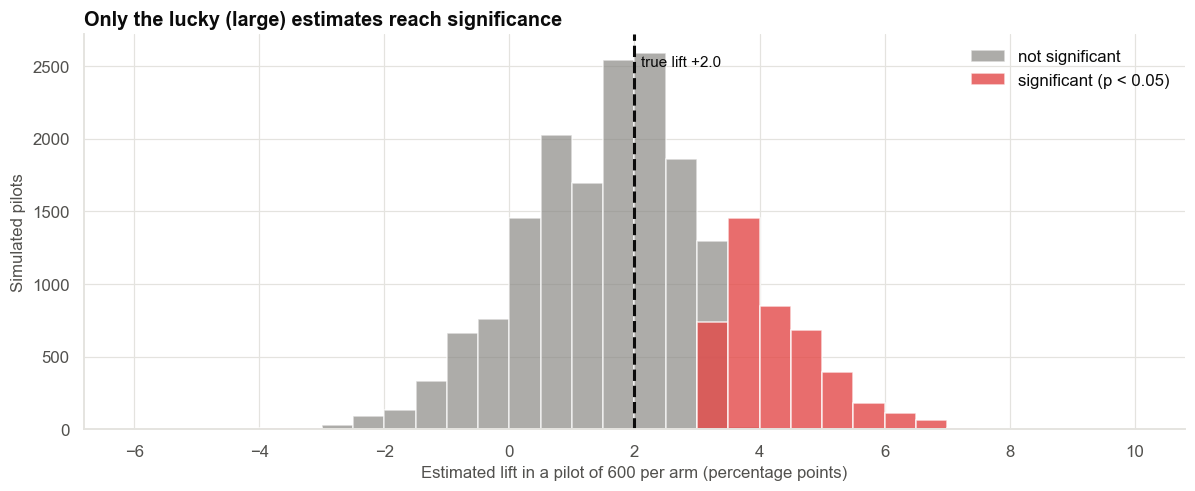

In [13]:
R = 20_000
x_c = rng.binomial(600, 0.080, R); x_o = rng.binomial(600, 0.100, R)
p_c, p_o = x_c / 600, x_o / 600
pb = (x_c + x_o) / 1200
z = (p_o - p_c) / np.sqrt(pb * (1 - pb) * (2 / 600))
sig = np.abs(z) > 1.96
diff = 100 * (p_o - p_c)
tm = pd.DataFrame({"value": [sig.mean(), diff.mean(), diff[sig].mean(), diff[sig].mean() / 2.0, (diff[sig] < 0).mean(), (diff[sig & (diff > 0)] > 100 * be_b).mean()]},
                  index=["power: share of pilots with p < 0.05", "average estimated lift, all pilots (true +2.0 pp)", "average estimated lift among SIGNIFICANT pilots (pp)",
                         "exaggeration ratio (Type M): significant estimate ÷ true lift", "Type S: share of significant results with the WRONG sign",
                         "share of positive significant pilots whose estimate exceeds break-even"])
save_table(tm, "type_s_type_m", PATHS["tables"])
display(tm)
fig, ax = plt.subplots(figsize=(11, 4.6))
ax.hist(diff[~sig], bins=np.linspace(-6, 10, 33), color=INK_MUTED, alpha=0.7, label="not significant")
ax.hist(diff[sig], bins=np.linspace(-6, 10, 33), color=COLORS["red"], alpha=0.8, label="significant (p < 0.05)")
ax.axvline(2.0, color=INK, ls="--", lw=2); ax.text(2.1, ax.get_ylim()[1] * 0.92, "true lift +2.0", fontsize=10)
ax.set(xlabel="Estimated lift in a pilot of 600 per arm (percentage points)", ylabel="Simulated pilots", title="Only the lucky (large) estimates reach significance")
ax.legend(frameon=False)
fig.tight_layout()
save_fig(fig, "fig06_type_m", PATHS["figures"])
plt.show()

**Observation.** With a true lift of +2 points, only about **one pilot in four** is significant. The significant ones
have an **average estimated lift of about 4.2 points**, about **twice** the truth, and a small share even have the
wrong sign.

**Interpretation.** Statistical significance in a **low-power** study is a **filter for exaggeration** (the winner's
curse of Case 19). Had our pilot been "lucky" and significant, we would have launched believing in +4 points. The
safeguards are the same: **report the CI**, plan with **conservative** (shrunken) effect sizes, and **replicate**.

## Section 10 — Decision matrix and how to communicate

| | **Effect is practically relevant** (CI reaches above break-even) | **Effect is not relevant** (CI entirely below break-even) |
|---|---|---|
| **Statistically significant** | **Act.** Launch, using the interval for planning | **Real but not worth it** (A): don't build; maybe a cheaper version |
| **Not significant** | **Inconclusive** (B): the pilot is underpowered; extend if the value of information is positive | **No evidence of a useful effect:** stop (the CI is narrow and lies below break-even, or inside an equivalence margin) |

| Statement | When it is correct |
|---|---|
| "The effect is statistically significant" | The interval excludes 0 (the effect is unlikely to be exactly zero) |
| "The effect is practically significant" | The interval lies above the **pre-specified** practical threshold |
| "No effect was found" | The test was not significant (**not** the same as "there is no effect") |
| "There is no meaningful effect" | The **whole CI** lies within the **equivalence margin** around zero (or below break-even) |
| "The result is inconclusive" | The CI includes both worthless and valuable effects |

**How to report each result (suggested wording)**

> **A.** *The redesign increased conversion by 0.10 percentage points (95% CI 0.05 to 0.15; p = 0.0001). This is
> statistically clear but well below the 0.20-point break-even; the whole interval lies below it, so the expected
> net value is negative (about −₹17 lakh a year). We recommend not building it.*
>
> **B.** *The pilot estimated a lift of 2.0 percentage points (95% CI −1.4 to +5.4; p = 0.25). The pilot was too small
> to be conclusive: it had about 21% power for a 2-point effect. The offer is more likely than not to be worth its
> cost (break-even 1.3 points), but with substantial uncertainty. We recommend a follow-up test of about 4,000 customers
> per arm.*

**Rules**

1. **State the practical threshold before the experiment** (break-even, or the smallest effect worth acting on).
2. **Report the effect size with a CI**, never a p-value alone.
3. **Interpret the CI against the threshold.**
4. **For non-significant results, report the power / MDE and the range of compatible effects.**
5. **Never say "no effect" from a non-significant result** unless an equivalence test supports it.
6. **Plan sample sizes** for the smallest effect that matters, not for the effect you hope for.

## Section 11 — Grading against the truth

In [14]:
key = pd.read_csv(PATHS["data"] / "answer_key_teaching_only.csv").set_index("experiment")
t_a, t_b = key.loc["A (checkout)", "true_lift_pp"], key.loc["B (fee waiver)", "true_lift_pp"]
g = pd.DataFrame({"true lift (pp)": [t_a, t_b], "estimated lift (pp)": [100 * ra["diff"], 100 * rb["diff"]],
                  "95% CI low": [100 * ra["ci"][0], 100 * rb["ci"][0]], "95% CI high": [100 * ra["ci"][1], 100 * rb["ci"][1]],
                  "p-value": [ra["p"], rb["p"]], "break-even (pp)": [100 * be_a, 100 * be_b],
                  "true net value per year (₹ lakh)": [(t_a / 100 * visits_year * A_MARGIN - cost_year) / LAKH, (t_b / 100 * B_MARGIN - B_COST) * B_ELIGIBLE / LAKH]},
                 index=["A: checkout redesign", "B: fee-waiver offer"])
g["CI covers the truth?"] = (g["95% CI low"] <= g["true lift (pp)"]) & (g["true lift (pp)"] <= g["95% CI high"])
g["true lift above break-even?"] = g["true lift (pp)"] > g["break-even (pp)"]
save_table(g, "grading", PATHS["tables"])
g

,true lift (pp),estimated lift (pp),95% CI low,95% CI high,p-value,break-even (pp),true net value per year (₹ lakh),CI covers the truth?,true lift above break-even?
A: checkout redesign,0.10000,0.09834,0.04875,0.14793,0.00010,0.20418,-16.32760,True,False
B: fee-waiver offer,2.00000,2.00000,-1.39293,5.39293,0.24821,1.33333,120.00000,True,True


**Observation.** In truth, A's lift is **+0.10 points**, below break-even, and its true net value is **negative** (about −₹16
lakh a year): the analyst's "launch" would have lost money. B's true lift is **+2.0 points**, above break-even, with a
**positive** net value (about +₹120 lakh a year across 200,000 eligible customers): the analyst's "drop it" would have
thrown away a profitable offer. The p-values pointed to exactly the wrong decision on **both** experiments, and
the CIs compared with break-even pointed to the right one (for B, to a larger test).

## Section 12 — Results

In [15]:
summary = pd.DataFrame({"Value": [
    f"lift {100 * ra['diff']:+.2f} pp (95% CI {100 * ra['ci'][0]:.2f} to {100 * ra['ci'][1]:.2f}), relative {100 * ra['diff'] / ra['p0']:.1f}%, p {fmt_p(ra['p'])}, Cohen's h {cohens_h(ra['p1'], ra['p0']):.3f}",
    f"break-even {100 * be_a:.2f} pp; net value {net(ra['diff']) / LAKH:+.0f} lakh/year (CI {net(ra['ci'][0]) / LAKH:+.0f} to {net(ra['ci'][1]) / LAKH:+.0f}); P(true lift below break-even) {fmt_p(p_below)}".replace("-", "−"),
    f"lift {100 * rb['diff']:+.1f} pp (95% CI {100 * rb['ci'][0]:+.1f} to {100 * rb['ci'][1]:+.1f}), p = {rb['p']:.2f}; power at +2 pp {pw_tbl.loc[2.0, 'power with 600 per arm']:.0%}".replace("-", "−"),
    f"P(lift > break-even) {post.iloc[0]['P(lift > break-even)']:.0%} (flat prior), {post.iloc[1]['P(lift > break-even)']:.0%} (weak prior); expected net value ₹{post.iloc[0]['expected net value per customer offered (₹)']:+.0f} per customer offered",
    f"launch now ₹{voi.iloc[0, 0]:.0f} lakh; bigger test then decide ₹{voi.iloc[2, 0]:.0f} lakh; perfect information ₹{voi.iloc[3, 0]:.0f} lakh per year",
    f"power {tm.iloc[0, 0]:.0%}; significant estimates average {tm.iloc[2, 0]:.1f} pp = {tm.iloc[3, 0]:.1f}× the truth",
]}, index=["A", "A: economics", "B", "B: decision", "B: value of information", "Type M"])
save_table(summary, "results_summary", PATHS["tables"])
summary

,Value
A,"lift +0.10 pp (95% CI 0.05 to 0.15), relative ..."
A: economics,break−even 0.20 pp; net value −17 lakh/year (C...
B,"lift +2.0 pp (95% CI −1.4 to +5.4), p = 0.25; ..."
B: decision,"P(lift > break-even) 65% (flat prior), 54% (we..."
B: value of information,launch now ₹30 lakh; bigger test then decide ₹...
Type M,power 23%; significant estimates average 4.2 p...


## Section 13 — Interpretation

- **A** is a textbook case of *statistically significant, practically irrelevant*. Sample size made a tiny effect
  detectable; the economics make it worthless.
- **B** is a textbook case of *non-significant, but promising*. The pilot was too small; the interval contains both
  worthless and valuable effects; the posterior probability that it is worth having is better than even.
- **Both p-values pointed to the wrong action.** The decision-relevant information was in the **effect size**, the
  **interval**, the **break-even** and the **power**.

## Section 14 — What can we say?

| ✅ We can say | ❌ We cannot say |
|---|---|
| "The redesign lifts conversion by 0.10 points (95% CI 0.05–0.15); that is below the 0.20-point break-even." | "The redesign works, so launch" (significance ≠ worth it). |
| "The fee-waiver pilot is inconclusive: the lift could plausibly be anywhere from −1.4 to +5.4 points." | "The fee waiver has no effect." |
| "The offer is more likely than not to be worth its cost, under a weakly informative prior." | "The offer will make money." |
| "A follow-up test has positive expected value." | "We have proved the offer works." |

## Section 15 — Business interpretation

- **A:** do not build. If the team still wants the redesign for other reasons, ask for a cheaper version (a build cost
  below about ₹10 lakh would break even at this lift: 3 years of ₹15 lakh benefit, less ₹12 lakh a year to run).
- **B:** run a **follow-up test** before deciding. 4,000 customers per arm has 80% power only for lifts of about 1.8 points or more; a test powered for the 1.3-point break-even needs about 7,000 per arm.
- **Process:** every experiment readout should include the **effect size, its CI, the break-even and the power**, and
  pre-register the practical threshold.

## Section 16 — Limitations

- Break-even calculations depend on assumed margins and costs, and on projecting the lift unchanged for three years.
- The Bayesian analysis uses a stated prior (N(0, 3 pp)); different priors give somewhat different probabilities.
- The value-of-information calculation assumes the follow-up test is run once, with a fixed sample size.
- Synthetic data.

## Section 17 — Final recommendation

> **Do not build the checkout redesign (A):** the lift is real but a fraction of what it costs to deliver. **Do not
> drop the fee waiver (B):** the pilot was too small to say. **Run a follow-up test** (4,000 per arm detects about 1.8 points; about 7,000 per arm is needed to detect the break-even lift), and decide on the **interval versus ₹-threshold**, not on p < 0.05. Add **effect
> size, CI, break-even and power** to every experiment readout.

## Section 18 — What would I do next?

1. Specify and **pre-register** the smallest worthwhile effect for every future test.
2. Run the **B follow-up** with sequential or fixed-sample design (Case 04) powered for the break-even lift (about 7,000 per arm).
3. Build an **experiment-readout template** that prints the CI against the threshold and the power, not just the p-value.
4. For A, ask engineering for a **cheaper variant**; test it only if its break-even is within the CI.
5. Continue to **Case 23** (bootstrapping skewed metrics).